In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import clm_sep as clm
from models import hgm_sep as hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

In [3]:
def cosine_lr(step, warmup_steps, total_steps, lr_max, lr_min_ratio):
    if step < warmup_steps:
        return lr_max * step / warmup_steps
    progress = (step - warmup_steps) / (total_steps - warmup_steps)
    lr_min = lr_max * lr_min_ratio
    return lr_min + 0.5*(lr_max - lr_min)*(1 + math.cos(math.pi*progress))

In [4]:
def train_numerical_model(model, splits, B_ll, N_res, N_man=None, hyperparameters=None):
	is_hgm = model.get_type()

	# Hyperparamters ============
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	if hyperparameters is None:
		hyperparameters = {
			'max_epochs': 1000,
			'max_patience': 1000,
			'learning_rate': 1E-3, #1E-4, #0.0001, #0.005, # 0.02
			'w1_reg_lambda': 0., #1E-3, #0.002,
			'w2_reg_lambda': 0., #1E-4, #0.5, #0.01,
		}

	max_epochs = hyperparameters['max_epochs']
	max_patience = hyperparameters['max_patience']

	learning_rate = hyperparameters['learning_rate']

	reg_lambdas = hyperparameters['w1_reg_lambda'], hyperparameters['w2_reg_lambda']
	# ===========================

	n_neurons = N_res.shape[1]
	if is_hgm: n_dimensions = N_man.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# training loop =======================================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mse_losses_per_split = list()
	mse_losses_tr_per_split = list()
	__grads_per_split = list()
	for s_id, (train, test) in enumerate(splits):
		# splitting and initializing ========================= (this also moves the data to the GPU)
		B_ll_train, B_ll_test = jnp.array(B_ll[train]), jnp.array(B_ll[test])
		if is_hgm: N_man_train, N_man_test = jnp.array(N_man[train]), jnp.array(N_man[test])
		N_res_train, N_res_test = jnp.array(N_res[train]), jnp.array(N_res[test])

		if is_hgm:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_behaviors_ll, n_neurons))
		optimizer = optax.adam(learning_rate)
		opt_state = optimizer.init(params)
		# ==========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, B_ll_test, N_man_test, N_res_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()]
			mse_losses = [model.mse_loss_fn(params, B_ll_test, N_man_test, N_res_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()]
		else:
			losses = [model.loss_fn(params, B_ll_test, N_res_test, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()]
			mse_losses = [model.mse_loss_fn(params, B_ll_test, N_res_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, B_ll_train, N_res_train).item()]
		__grads = list()

		best_params = params
		best_loss = sys.float_info.max
		best_loss_tr = sys.float_info.max
		best_mse_loss = sys.float_info.max
		best_mse_loss_tr = sys.float_info.max

		# lr_step = 0
		patience = 0
		for epoch in range(max_epochs):
			# lr = cosine_lr(epoch, max_epochs / 10, max_epochs, learning_rate, 1E-6)
			# optimizer = optax.adam(lr)

			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, B_ll_train, N_man_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_test, N_man_test, N_res_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_man_train, N_res_train, reg_lambdas).item()
				mse_loss = model.mse_loss_fn(params, B_ll_test, N_man_test, N_res_test).item()
				mse_loss_tr = model.mse_loss_fn(params, B_ll_train, N_man_train, N_res_train).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, B_ll_train, N_res_train, reg_lambdas)
				loss = model.loss_fn(params, B_ll_test, N_res_test, reg_lambdas).item()
				loss_tr = model.loss_fn(params, B_ll_train, N_res_train, reg_lambdas).item()
				mse_loss = model.mse_loss_fn(params, B_ll_test, N_res_test).item()
				mse_loss_tr = model.mse_loss_fn(params, B_ll_train, N_res_train).item()
			__grads.append(__grad)

			# early stopping ================
			if loss < best_loss:
				patience = 0

				best_params = params
				best_loss = loss
				best_loss_tr = loss_tr
				best_mse_loss = mse_loss
				best_mse_loss_tr = mse_loss_tr
			else:
				patience += 1
				if patience > max_patience:
					params = best_params
					losses = losses + [best_loss for _ in range(max_epochs - epoch)]
					losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - epoch)]
					mse_losses = mse_losses + [best_mse_loss for _ in range(max_epochs - epoch)]
					mse_losses_tr = mse_losses_tr + [best_mse_loss_tr for _ in range(max_epochs - epoch)]

					print(f'\nStopped after {epoch} epochs.', end='')
					break

					# lr_step += 1
					# optimizer = optax.adam(learning_rate / (10 ** lr_step))
					# patience = 0
					# print(f'\nReduced learning rate from {learning_rate / (10 ** (lr_step - 1))} to {learning_rate / (10 ** lr_step)} after epoch {epoch} in split {s_id}', end='')

			losses.append(loss)
			losses_tr.append(loss_tr)
			mse_losses.append(mse_loss)
			mse_losses_tr.append(mse_loss_tr)
			# ===============================

		params_per_split.append(params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mse_losses_per_split.append(mse_losses)
		mse_losses_tr_per_split.append(mse_losses_tr)

		__grads_per_split.append(__grads)

		print(f'Split {s_id} completed.')

		# predicting and scoring ========================================================================
		if is_hgm:
			score_per_neuron = model.score_fn(params, B_ll_test, N_man_test, N_res_test)
		else:
			score_per_neuron = model.score_fn(params, B_ll_test, N_res_test)
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mse_losses_per_split), np.array(mse_losses_tr_per_split), __grads_per_split

In [5]:
def train_numerical_models(model, filenames, discrete_states, eigenworms, traces_residual, neural_modes=None):
	models_params = list()
	models_scores = list()
	models_losses = list()
	models_losses_tr = list()
	models_mse_losses = list()
	models_mse_losses_tr = list()
	__models_grads = list()
	__splits_ids = list()

	for i in range(len(filenames)):
		print(f'{i + 1}/{len(filenames)}: {filenames[i]}  ', end='')

		splits = list(StratifiedKFold(n_splits=5).split(np.zeros(eigenworms[i].values.shape[0]), discrete_states[i]['REV'].values))

		(params_per_split,
		 neuron_scores_per_split,
		 losses_per_split, losses_tr_per_split,
		 mse_losses_per_split, mse_losses_tr_per_split,
		 __grads_per_split) = train_numerical_model(model, splits,
													eigenworms[i].values,
													traces_residual[i].values,
													neural_modes[i].values if neural_modes is not None else None)

		models_params.append(params_per_split)
		models_scores.append(neuron_scores_per_split)
		models_losses.append(losses_per_split)
		models_losses_tr.append(losses_tr_per_split)
		models_mse_losses.append(mse_losses_per_split)
		models_mse_losses_tr.append(mse_losses_tr_per_split)
		__models_grads.append(__grads_per_split)
		__splits_ids.append(splits)

	return models_params, models_scores, models_losses, models_losses_tr, models_mse_losses, models_mse_losses_tr, __models_grads, __splits_ids

In [6]:
def assemble(filenames, traces, clm_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_clm_new = score_clm_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_clm_new, score_hgm_new)
				else:
					score_clm_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
worm_id = 0  # 33

# selection_n = ['AVAR', 'AVEL', 'BAGR', 'BAGL', 'URYVR', 'URYVL']  # high m portion
# selection_n = ['VB02', 'SMDDR', 'SMDDL', 'RMDDR', 'RMDDL', 'SMDVR']  # high c portion for worm 24
# selection_n = ['DB01', 'VB02', 'RMDDL', 'RMDDR', 'SMDVR', 'RMER']  # high c portion for worm 33
# selection_n = ['RMDDL', 'DB01', 'VB02']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE'] # ['REV', 'VENTRAL_TURN']

# dims = 2
dims_generation = 2

weights = (0.5, 2.)

In [8]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, slice=(24, 33 + 1))

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

In [9]:
(neural_modes_gcamp, _,
 traces_manifold_gcamp, _,
 cca_loadings_man_gcamp,
 vars_expl_man_gcamp, vars_expl_man_rs_gcamp) = train_utils.get_manifolds(traces_gcamp,
																		  discrete_states_gcamp,
																		  n_cc=2, n_pc=5)

# plot_utils.plot_manifolds(filenames_gcamp,
# 						  neural_modes_gcamp,
# 						  discrete_states_gcamp,
# 						  vars_expl_man_gcamp, vars_expl_man_rs_gcamp,
# 						  n_plots=None, plots_per_row=1)

traces_residual_gcamp = [pd.DataFrame(data=trace.values - trace_manifold.values, columns=trace.columns) for trace, trace_manifold in zip(traces_gcamp, traces_manifold_gcamp)]

In [10]:
# traces_gcamp[worm_id] = traces_gcamp[worm_id][selection_n]
# traces_residual_gcamp[worm_id] = traces_residual_gcamp[worm_id][selection_n]

In [11]:
# plot_utils.plot_traces(f'[{filenames_gcamp[worm_id]}] traces res',
# 					   discrete_states_gcamp[worm_id]['REV'],
# 					   traces_residual_gcamp[worm_id][selection_n],
# 					   n_plots=None, plots_per_row=2)

In [12]:
# traces_gcamp = [df.loc[:, ~df.columns.to_series().str.strip().eq('').fillna(True)] for df in traces_gcamp]
# traces_residual_gcamp = [df.loc[:, ~df.columns.to_series().str.strip().eq('').fillna(True)] for df in traces_residual_gcamp]

In [13]:
(clm_models_params_gcamp,
 clm_models_scores_gcamp,
 clm_models_losses_gcamp, clm_models_losses_tr_gcamp,
 clm_models_mse_losses_gcamp, clm_models_mse_losses_tr_gcamp,
 __clm_models_grads_gcamp, __clm_splits_gcamp) = train_numerical_models(clm,
													filenames_gcamp,
													discrete_states_gcamp,
													eigenworms_gcamp,
													traces_residual_gcamp)

1/10: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
2/10: 2023-11-21_15-05_wt_worm5-2023-11-21_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
3/10: 2024-01-30_17-00_wt_worm2-2024-01-30_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
4/10: ZIM2165_Gcamp7b_worm2-2022-11-30_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
5/10: ZIM2165_Gcamp7b_worm3-2022-12-05_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
6/10: 2022-11-23_worm10_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
7/10: 2022-11-23_worm11_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed

In [14]:
(hgm_models_params_gcamp,
 hgm_models_scores_gcamp,
 hgm_models_losses_gcamp, hgm_models_losses_tr_gcamp,
 hgm_models_mse_losses_gcamp, hgm_models_mse_losses_tr_gcamp,
 __hgm_models_grads_gcamp, __hgm_splits_gcamp) = train_numerical_models(hgm,
													filenames_gcamp,
													discrete_states_gcamp,
													eigenworms_gcamp,
													traces_residual_gcamp,
													neural_modes_gcamp)

1/10: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
2/10: 2023-11-21_15-05_wt_worm5-2023-11-21_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
3/10: 2024-01-30_17-00_wt_worm2-2024-01-30_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
4/10: ZIM2165_Gcamp7b_worm2-2022-11-30_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
5/10: ZIM2165_Gcamp7b_worm3-2022-12-05_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
6/10: 2022-11-23_worm10_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed.
Split 4 completed.
7/10: 2022-11-23_worm11_no_image_data  Split 0 completed.
Split 1 completed.
Split 2 completed.
Split 3 completed

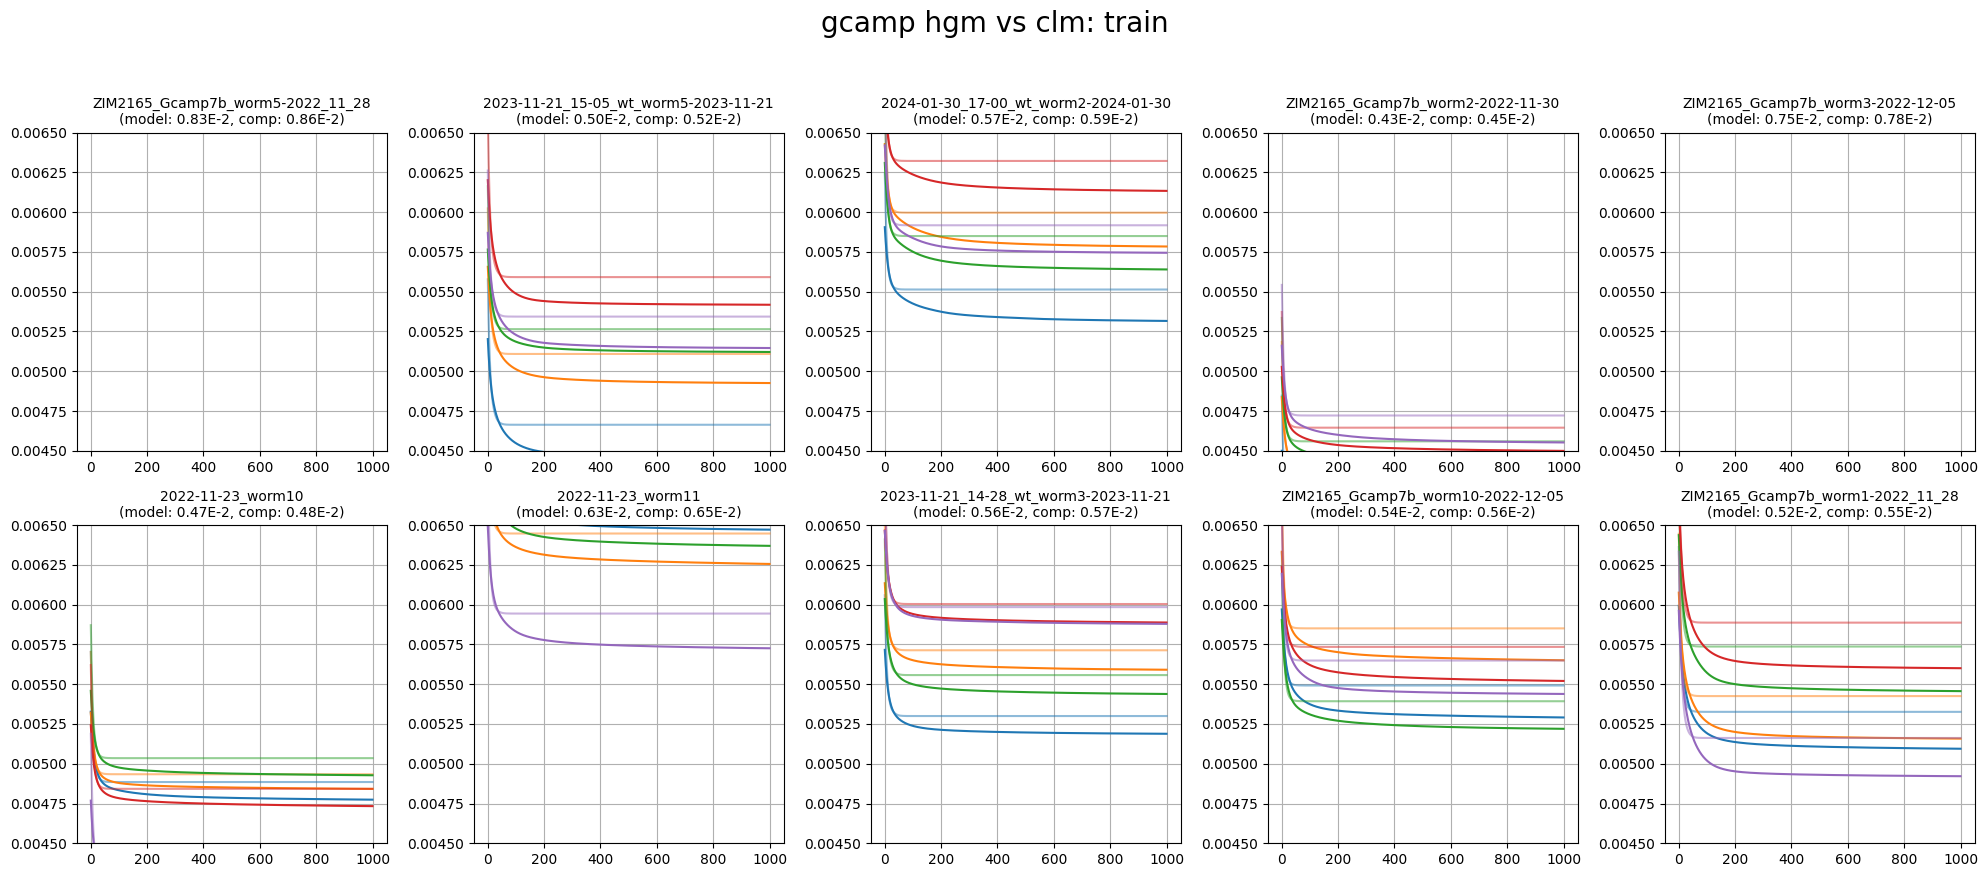

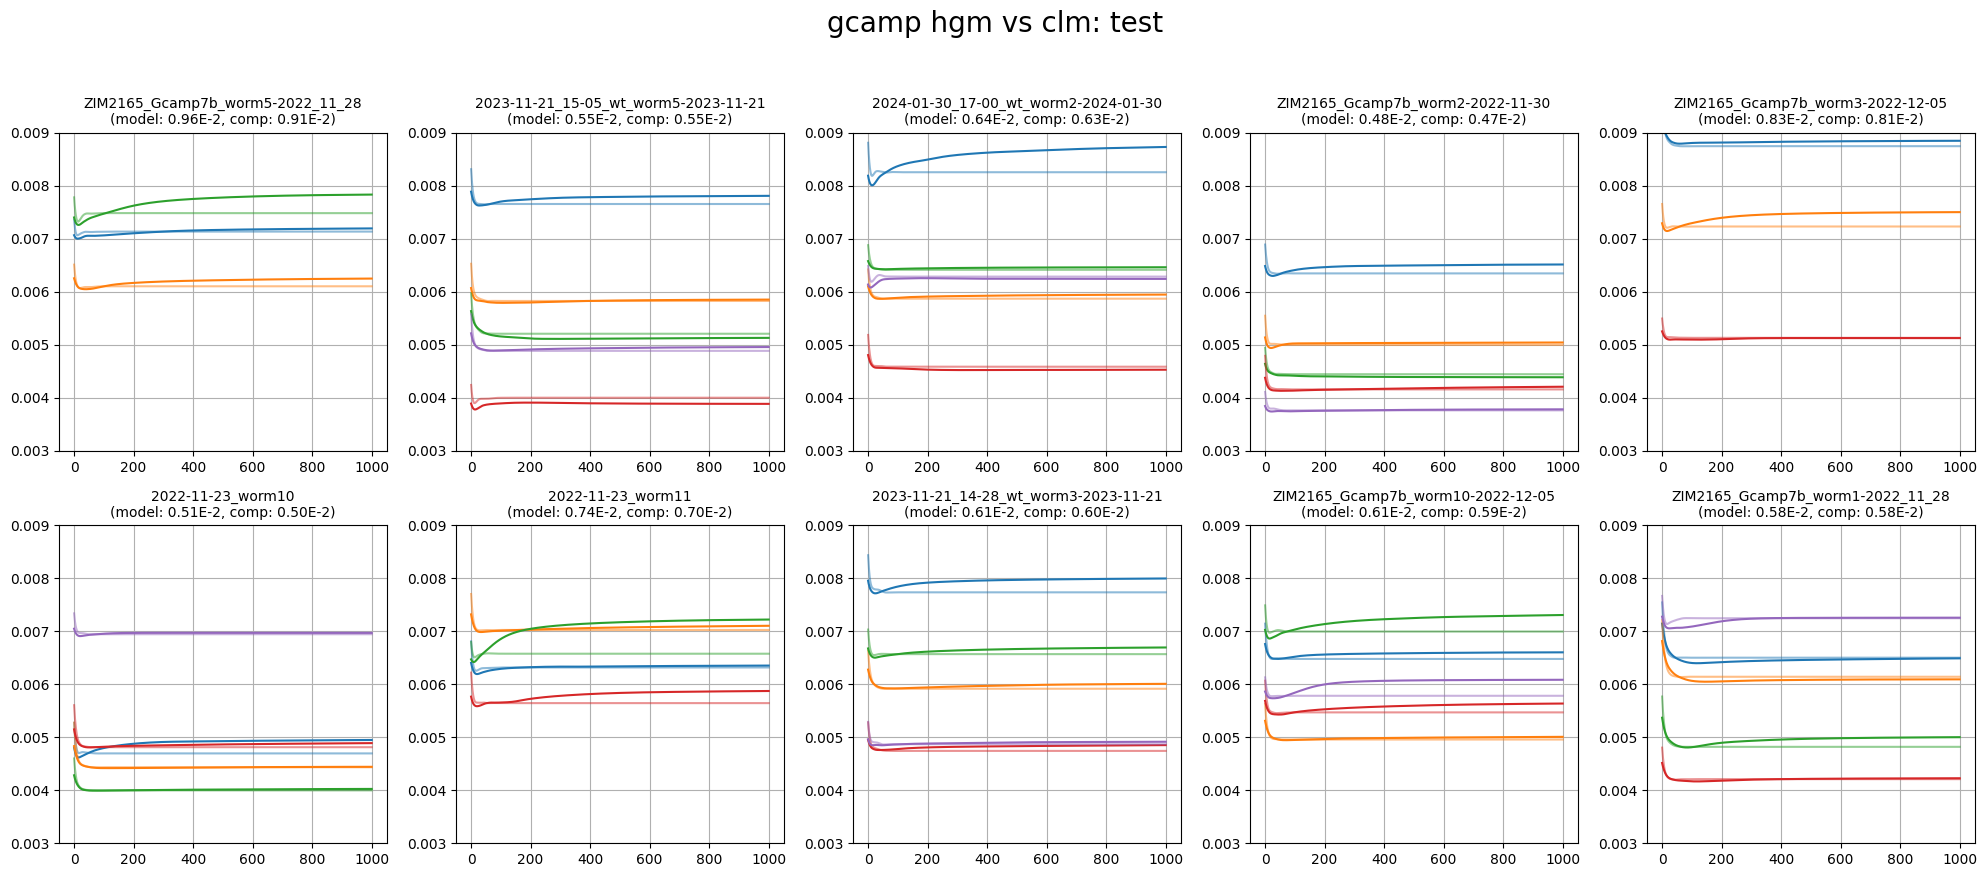

In [15]:
plot_utils.plot_losses_splits('gcamp hgm vs clm: train',
							  filenames_gcamp,
							  hgm_models_mse_losses_tr_gcamp, clm_models_mse_losses_tr_gcamp,
							  plots_per_row=5, ylimits=(0.0045, 0.0065))

plot_utils.plot_losses_splits('gcamp hgm vs clm: test',
							  filenames_gcamp,
							  hgm_models_mse_losses_gcamp, clm_models_mse_losses_gcamp,
							  plots_per_row=5, ylimits=(0.003, 0.009))

In [16]:
clm_models_avg_scores = [pd.DataFrame(data=np.mean(scores, axis=0).reshape(1, -1), columns=traces.columns) for traces, scores in zip(traces_gcamp, clm_models_scores_gcamp)]
hgm_models_avg_scores = [pd.DataFrame(data=np.mean(scores, axis=0).reshape(1, -1), columns=traces.columns) for traces, scores in zip(traces_gcamp, hgm_models_scores_gcamp)]

# clm_models_avg_scores = [df.loc[:, ~df.columns.to_series().str.strip().eq('').fillna(True)] for df in clm_models_avg_scores]
# hgm_models_avg_scores = [df.loc[:, ~df.columns.to_series().str.strip().eq('').fillna(True)] for df in hgm_models_avg_scores]

print(clm_models_avg_scores[0].values.mean(), hgm_models_avg_scores[0].values.mean())

-0.28145853972435 -0.33798875510692594


In [17]:
# clm_predicted_traces = [[
# 	pd.DataFrame(data=clm.predict(eigenworms_gcamp[i].iloc[split_ids[1]].values, params['W']),
# 				 columns=traces_gcamp[i].columns) for split_ids, params in zip(__clm_splits_gcamp[i], clm_models_params_gcamp[i])
# ] for i in range(len(traces_gcamp))]
#
# hgm_predicted_traces = [[
# 	pd.DataFrame(data=hgm.predict(eigenworms_gcamp[i].iloc[split_ids[1]].values, neural_modes_gcamp[i].iloc[split_ids[1]].values, params['W1'], params['W2']),
# 				 columns=traces_gcamp[i].columns) for split_ids, params in zip(__hgm_splits_gcamp[i], hgm_models_params_gcamp[i])
# ] for i in range(len(traces_gcamp))]

In [18]:
# selection_n = ['RMDDL', 'DB01', 'VB02']
#
# plot_utils.plot_traces_splits('clm predictions',
# 							  discrete_states_gcamp[worm_id]['REV'],
# 							  traces_residual_gcamp[worm_id][selection_n],
# 							  clm_predicted_traces[worm_id],
# 							  ylimits=None, plots_per_row=1)
#
# plot_utils.plot_traces_splits('hgm predictions',
# 							  discrete_states_gcamp[worm_id]['REV'],
# 							  traces_residual_gcamp[worm_id][selection_n],
# 							  hgm_predicted_traces[worm_id],
# 							  ylimits=None, plots_per_row=1)

In [19]:
# for i in range(5):
# 	plot_utils.plot_traces(f's{i}',
# 						   discrete_states_gcamp[worm_id]['REV'],
# 						   [traces_residual_gcamp[worm_id][selection_n], hgm_predicted_traces[worm_id][i][selection_n], clm_predicted_traces[worm_id][i][selection_n]],
# 						   n_plots=len(selection_n), plots_per_row=1, ylimits=None)

In [20]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, clm_models_scores_gcamp, hgm_models_scores_gcamp)

In [21]:
# nsgcamp = np.array(list(neuron_scores_gcamp.values())).reshape(40, 2)
# nsg_ms = np.mean(nsgcamp, axis=0)
# print(nsg_ms)

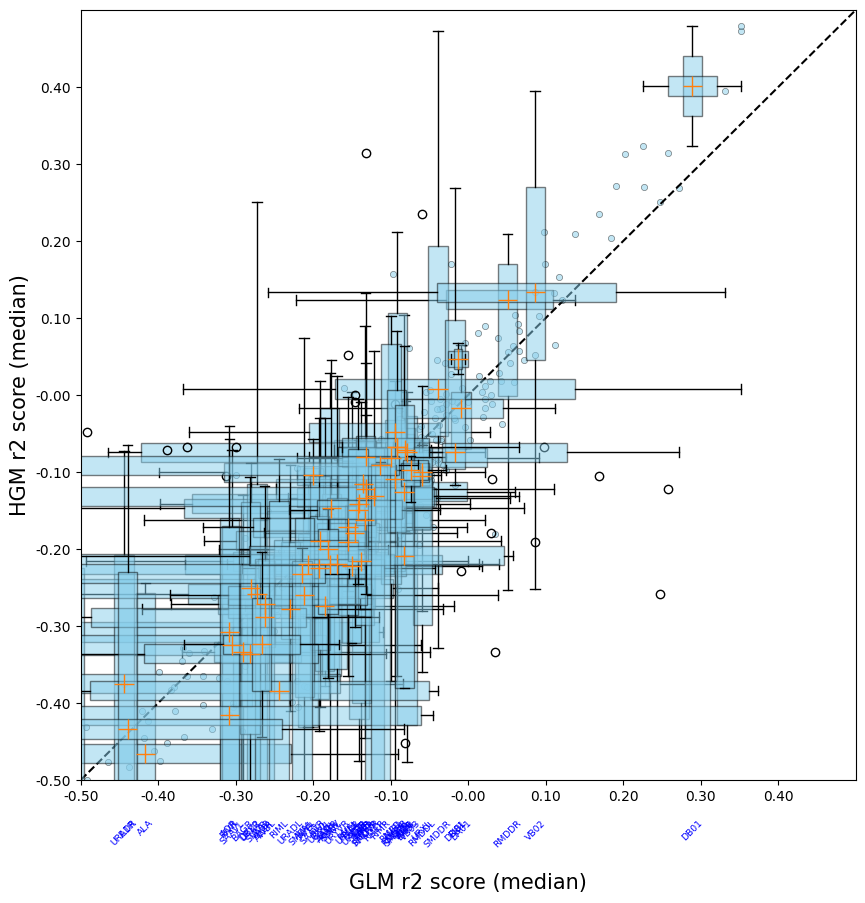

In [22]:
plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
								 scale=10, limits=(-0.5, 0.5, -0.5, 0.5))